
# Test sur les nouvelles données

`all_tables_new.csv` contient 34 000 clients avec leur résultat réel. On le
traite comme s'il était inconnu : le modèle prédit, puis on compare avec la
réalité pour compter les bonnes et les mauvaises réponses.

| | Modèle dit | Réalité | Verdict |
|---|---|---|---|
| Client A | part | part | correct |
| Client B | reste | reste | correct |
| Client C | part | reste | incorrect (fausse alerte) |
| Client D | reste | part | incorrect (partant manqué) |

Entrées : `models/modele_churn_sklearn16.joblib` (notebook 06) et
`data/final/all_tables_new.csv`.



## 1. Chargement


In [1]:

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, roc_auc_score

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

modele = joblib.load(ROOT / 'models' / 'modele_churn_sklearn16.joblib')

donnees = pd.read_csv(ROOT / 'data' / 'final' / 'all_tables_new.csv',
                      keep_default_na=False, na_values=[''], low_memory=False)

print('modèle  :', type(modele).__name__)
print('données :', donnees.shape)


modèle  : HistGradientBoostingClassifier
données : (34000, 10)


In [2]:

X = donnees.drop(columns=['churn'])
y_reel = donnees['churn'].to_numpy()

print(f'{len(y_reel):,} clients')
print(f'  restent : {int((y_reel == 0).sum()):,}  ({(y_reel == 0).mean()*100:.1f} %)')
print(f'  partent : {int((y_reel == 1).sum()):,}  ({(y_reel == 1).mean()*100:.1f} %)')


34,000 clients
  restent : 24,853  (73.1 %)
  partent : 9,147  (26.9 %)



## 2. Prédiction

`predict_proba` donne une probabilité. Le seuil 0,5 la transforme en réponse
binaire : au-dessus le modèle annonce un départ, en-dessous il annonce un
maintien.

Les valeurs manquantes sont remplacées par 0, comme à l'entraînement.


In [3]:

X_rempli = X.copy()
for colonne in X_rempli.columns:
    X_rempli[colonne] = pd.to_numeric(X_rempli[colonne], errors='coerce').fillna(0)

print('valeurs manquantes avant :', int(X.isna().sum().sum()))
print('valeurs manquantes après :', int(X_rempli.isna().sum().sum()))

proba = modele.predict_proba(X_rempli)[:, 1]

print()
print(f'{len(proba):,} clients scorés')
print(f'  minimum : {proba.min()*100:>5.1f} %')
print(f'  médiane : {np.median(proba)*100:>5.1f} %')
print(f'  maximum : {proba.max()*100:>5.1f} %')


valeurs manquantes avant : 21872
valeurs manquantes après : 0

34,000 clients scorés
  minimum :   0.8 %
  médiane :   9.5 %
  maximum :  98.1 %


In [4]:

SEUIL = 0.5
y_predit = (proba >= SEUIL).astype(int)

print(f'seuil {SEUIL}')
print(f'  prédit "part"  : {int(y_predit.sum()):,} clients')
print(f'  prédit "reste" : {int((y_predit == 0).sum()):,} clients')


seuil 0.5
  prédit "part"  : 8,649 clients
  prédit "reste" : 25,351 clients



## 3. Comparaison avec la réalité


In [5]:

comparaison = pd.DataFrame({
    'churn_reel': y_reel,
    'churn_predit': y_predit,
    'probabilite': np.round(proba, 3),
})

comparaison['verdict'] = np.where(
    comparaison['churn_reel'] == comparaison['churn_predit'],
    'correct', 'incorrect')

print(comparaison.sample(8, random_state=1).to_string(index=False))


 churn_reel  churn_predit  probabilite   verdict
          1             1        0.870   correct
          1             1        0.808   correct
          0             0        0.056   correct
          0             0        0.044   correct
          0             0        0.078   correct
          1             0        0.107 incorrect
          1             1        0.779   correct
          0             0        0.074   correct


In [6]:

total = len(comparaison)
correctes = int((comparaison['verdict'] == 'correct').sum())
incorrectes = total - correctes

print(f'RÉSULTAT SUR {total:,} CLIENTS')
print()
print(f'  correctes   : {correctes:>7,}  ({correctes/total*100:>6.2f} %)')
print(f'  incorrectes : {incorrectes:>7,}  ({incorrectes/total*100:>6.2f} %)')


RÉSULTAT SUR 34,000 CLIENTS

  correctes   :  30,600  ( 90.00 %)
  incorrectes :   3,400  ( 10.00 %)



## 4. Matrice de confusion

Le total précédent ne distingue pas les deux types d'erreur.

| Erreur | Modèle dit | Réalité | Conséquence |
|---|---|---|---|
| Fausse alerte | part | reste | appel inutile |
| Partant manqué | reste | part | client perdu sans réaction |


In [7]:

tn, fp, fn, tp = confusion_matrix(y_reel, y_predit).ravel()

print('                 réalité')
print('              reste     part')
print(f'prédit reste {tn:>7,} {fn:>8,}')
print(f'       part  {fp:>7,} {tp:>8,}')
print()
print(f'  vrais négatifs    {tn:>7,}  correct')
print(f'  vrais positifs    {tp:>7,}  correct')
print(f'  fausses alertes   {fp:>7,}  incorrect')
print(f'  partants manqués  {fn:>7,}  incorrect')


                 réalité
              reste     part
prédit reste  23,402    1,949
       part    1,451    7,198

  vrais négatifs     23,402  correct
  vrais positifs      7,198  correct
  fausses alertes     1,451  incorrect
  partants manqués    1,949  incorrect


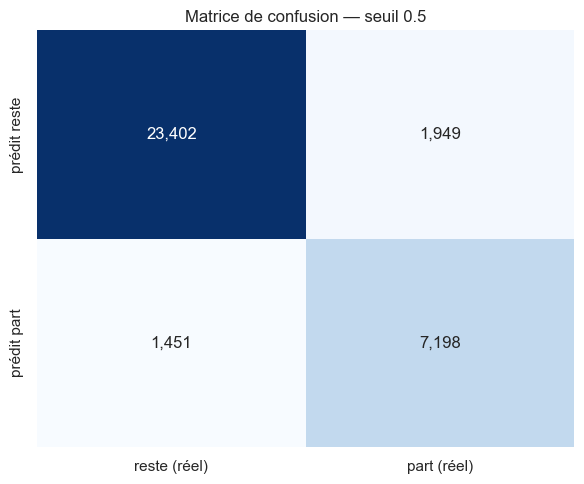

In [8]:

matrice = np.array([[tn, fn], [fp, tp]])

plt.figure(figsize=(6, 5))
sns.heatmap(matrice, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['reste (réel)', 'part (réel)'],
            yticklabels=['prédit reste', 'prédit part'],
            annot_kws={'size': 12})
plt.title(f'Matrice de confusion — seuil {SEUIL}')
plt.tight_layout()
plt.show()



## 5. Comparaison avec un modèle naïf

90 % de bonnes réponses ne suffisent pas à juger : il faut comparer avec un
modèle qui répond « personne ne part ».


In [9]:

y_naif = np.zeros(len(y_reel), dtype=int)
correct_naif = int((y_naif == y_reel).sum())

print('modèle naïf')
print(f'  correctes : {correct_naif:>7,}  ({correct_naif/total*100:.2f} %)')
print()
print('notre modèle')
print(f'  correctes : {correctes:>7,}  ({correctes/total*100:.2f} %)')
print()
print(f'  gain : {correctes - correct_naif:+,} réponses correctes')
print(f'         ({(correctes/total - correct_naif/total)*100:+.2f} points)')


modèle naïf
  correctes :  24,853  (73.10 %)

notre modèle
  correctes :  30,600  (90.00 %)

  gain : +5,747 réponses correctes
         (+16.90 points)



### Lecture

Le modèle naïf atteint déjà **73 %** parce que 73 % des clients restent. Notre
modèle fait **90 %**, soit +17 points. Ces points viennent de la détection des
9 147 partants, qu'un modèle naïf ignore complètement.

90 % de bonnes réponses ne signifie donc pas « 90 % de capacité à prédire » :
une grande partie vient du déséquilibre entre les deux classes.



## 6. Effet du seuil

Baisser le seuil détecte plus de partants mais produit plus de fausses
alertes. L'inverse en le montant.


In [10]:

print('seuil   correctes            incorrectes          précision  rappel')
for seuil in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= seuil).astype(int)
    tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_reel, pred).ravel()
    total_s = tn_s + fp_s + fn_s + tp_s
    correct_s = tn_s + tp_s
    precision = tp_s / (tp_s + fp_s) if (tp_s + fp_s) else 0
    rappel = tp_s / (tp_s + fn_s) if (tp_s + fn_s) else 0

    print(f'{seuil:>4.1f}   {correct_s:>7,} ({correct_s/total_s*100:>5.2f} %) '
          f'{total_s-correct_s:>7,} ({(total_s-correct_s)/total_s*100:>5.2f} %) '
          f'{precision:>9.1%} {rappel:>7.1%}')


seuil   correctes            incorrectes          précision  rappel
 0.1    25,268 (74.32 %)   8,732 (25.68 %)     51.3%   92.7%
 0.2    29,077 (85.52 %)   4,923 (14.48 %)     68.4%   85.8%
 0.3    30,141 (88.65 %)   3,859 (11.35 %)     77.1%   82.2%
 0.4    30,467 (89.61 %)   3,533 (10.39 %)     81.3%   79.7%
 0.5    30,600 (90.00 %)   3,400 (10.00 %)     83.2%   78.7%
 0.6    30,564 (89.89 %)   3,436 (10.11 %)     84.8%   76.1%
 0.7    30,273 (89.04 %)   3,727 (10.96 %)     86.9%   69.8%


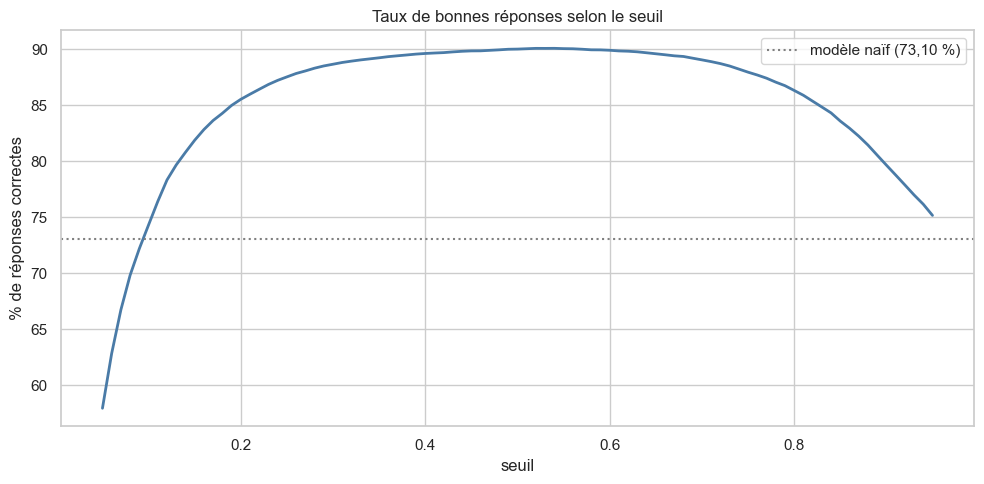

meilleur taux : 90.07 % au seuil 0.54


In [11]:

seuils = np.arange(0.05, 0.96, 0.01)
taux = [(proba >= s).astype(int).__eq__(y_reel).mean() * 100 for s in seuils]

plt.figure(figsize=(10, 5))
plt.plot(seuils, taux, linewidth=2, color='#4a7ba7')
plt.axhline(73.10, color='gray', linestyle=':', linewidth=1.5,
            label='modèle naïf (73,10 %)')
plt.xlabel('seuil')
plt.ylabel('% de réponses correctes')
plt.title('Taux de bonnes réponses selon le seuil')
plt.legend()
plt.tight_layout()
plt.show()

meilleur = int(np.argmax(taux))
print(f'meilleur taux : {taux[meilleur]:.2f} % au seuil {seuils[meilleur]:.2f}')



Le seuil qui maximise le nombre de bonnes réponses se situe autour de **0,54**
(environ 90 %). Ce n'est pas forcément le bon choix métier : il n'alerte que
sur les cas très sûrs et laisse passer beaucoup de partants.



## 7. Résultat par population


In [12]:

statut = X['STATUT'].to_numpy()

print(f'RÉSULTATS PAR POPULATION (seuil {SEUIL})')

for nom, masque in [('actifs', statut == 0), ('suspendus', statut == 1)]:
    y_p = y_reel[masque]
    pred_p = y_predit[masque]
    total_p = len(y_p)
    correct_p = int((y_p == pred_p).sum())
    naif_p = int((y_p == 0).sum())

    print()
    print(f'{nom} — {total_p:,} clients')
    print(f'  correctes   : {correct_p:>7,}  ({correct_p/total_p*100:>6.2f} %)')
    print(f'  incorrectes : {total_p-correct_p:>7,}  ({(total_p-correct_p)/total_p*100:>6.2f} %)')
    print(f'  naïf        : {naif_p/total_p*100:>6.2f} %')


RÉSULTATS PAR POPULATION (seuil 0.5)

actifs — 25,579 clients
  correctes   :  23,490  ( 91.83 %)
  incorrectes :   2,089  (  8.17 %)
  naïf        :  92.01 %

suspendus — 8,421 clients
  correctes   :   7,110  ( 84.43 %)
  incorrectes :   1,311  ( 15.57 %)
  naïf        :  15.64 %



### Lecture

Sur les **actifs**, le modèle fait presque aussi bien que le naïf (environ
92 %). Sur les **suspendus**, il fait beaucoup mieux (environ 84 % contre
16 %), mais c'est facile puisque 84 % d'entre eux partent vraiment.

Le taux de bonnes réponses n'est donc pas la bonne mesure pour juger ce
modèle. Il faut regarder la capacité à classer (AUC) et le gain sur une liste
d'appels.



## 8. Synthèse

Seuil 0,5, sur les 34 000 clients :

| | Nombre | Pourcentage |
|---|---|---|
| Réponses correctes | 30 600 | 90,00 % |
| Réponses incorrectes | 3 400 | 10,00 % |

| Type d'erreur | Nombre |
|---|---|
| Fausses alertes | 1 451 |
| Partants manqués | 1 949 |

### Référence

Un modèle qui répond « personne ne part » obtient **73,10 %**. Notre modèle
fait **90,00 %**, soit +16,9 points : il détecte 7 198 partants sur 9 147.

### Ce que ce taux ne dit pas

| Mesure | Valeur |
|---|---|
| AUC | 0,926 |
| Gain top 100 (actifs) | × 5 |

Le taux de bonnes réponses ne mesure pas la qualité du classement.

### En pratique

Pour cibler des relances, un seuil plus bas détecte plus de partants au prix
de plus de fausses alertes. Le bon seuil dépend du coût d'un appel comparé au
coût d'un client perdu.
